# EDA

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl
/kaggle/input/models/me0hu0l/plain-cnn-baseline-wm-811k/pytorch/default/1/plain_cnn_classifier_v1.pth


In [2]:
from sklearn.model_selection import KFold 
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from keras.utils import to_categorical

In [3]:
print("working directory is:", os.getcwd())
print("files in the working directory:", os.listdir("../input/datasets/qingyi/wm811k-wafer-map"))

working directory is: /kaggle/working
files in the working directory: ['LSWMD.pkl']


In [4]:
df = pd.read_pickle("/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 811457 entries, 0 to 811456
Data columns (total 6 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   waferMap        811457 non-null  object 
 1   dieSize         811457 non-null  float64
 2   lotName         811457 non-null  object 
 3   waferIndex      811457 non-null  float64
 4   trianTestLabel  811457 non-null  object 
 5   failureType     811457 non-null  object 
dtypes: float64(2), object(4)
memory usage: 37.1+ MB


In [5]:
df.tail()

,waferMap,dieSize,lotName,waferIndex,trianTestLabel,failureType
811452,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,23.0,[[Test]],[[Edge-Ring]]
811453,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1,...",600.0,lot47542,24.0,[[Test]],[[Edge-Loc]]
811454,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47542,25.0,[[Test]],[[Edge-Ring]]
811455,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,...",600.0,lot47543,1.0,[],[]
811456,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, 1, 1,...",600.0,lot47543,2.0,[],[]


In [6]:
df.drop(columns=["waferIndex"], inplace=True)

In [7]:
def find_dim(x):
        dim0= np.size(x,axis=0)
        dim1= np.size(x,axis=1)
        return dim0, dim1
df['waferMapDim'] = df['waferMap'].apply(find_dim)
df.sample(5)

,waferMap,dieSize,lotName,trianTestLabel,failureType,waferMapDim
216477,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1126.0,lot13736,[],[],"(36, 41)"
149788,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",3532.0,lot9609,[],[],"(64, 71)"
751044,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,...",506.0,lot45086,[[Training]],[[none]],"(27, 25)"
793176,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 2,...",562.0,lot46799,[[Test]],[[none]],"(29, 26)"
556165,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,...",515.0,lot34908,[],[],"(25, 27)"


In [8]:
max(df['waferMapDim'].unique()), min(df['waferMapDim'].unique())

((300, 202), (6, 21))

In [9]:
df['waferMapDim'].value_counts().head(10)

waferMapDim
(32, 29)    108687
(25, 27)     64083
(49, 39)     39323
(26, 26)     30078
(30, 34)     29513
(33, 33)     23886
(33, 29)     20276
(39, 37)     15327
(52, 59)     14812
(31, 31)     14569
Name: count, dtype: int64

In [10]:
df['waferMapDim'].value_counts().tail(10)

waferMapDim
(104, 116)    1
(36, 55)      1
(88, 62)      1
(51, 45)      1
(6, 21)       1
(21, 24)      1
(15, 3)       1
(21, 17)      1
(27, 15)      1
(18, 44)      1
Name: count, dtype: int64

In [11]:
len(df['waferMapDim'].unique().tolist())

632

In [12]:
df['failureNum'] = df.failureType
df['trainTestNum'] = df.trianTestLabel
mapping_type= {'Center': 0, 'Donut': 1, 'Edge-Loc': 2, 'Edge-Ring': 3, 'Loc': 4, 'Random': 5, 'Scratch': 6, 'Near-full': 7, 'none': 8}
mapping_traintest = {'Training': 0, 'Test': 1}
df.replace({'failureNum': mapping_type, 'trainTestNum': mapping_traintest}, inplace=True)

In [13]:
print(f"total wafers: {df.shape[0]}")
tol_wafers = df.shape[0]

total wafers: 811457


In [14]:
df_withlabel = df[(df['failureNum']>=0) & (df['failureNum']<=8)]
df_withlabel = df_withlabel.reset_index()
df_withpattern = df[(df['failureNum']>=0) & (df['failureNum']<8)]
df_withpattern = df_withpattern.reset_index()
df_nonpattern = df[(df['failureNum']==8)]
df_nonpattern = df_nonpattern.reset_index()
print(f"total wafers with label: {df_withlabel.shape[0]}")
print(f"total wafers with pattern: {df_withpattern.shape[0]}")
print(f"total wafers non-pattern: {df_nonpattern.shape[0]}")

total wafers with label: 172950
total wafers with pattern: 25519
total wafers non-pattern: 147431


In [15]:
df_withpattern.waferMapDim.value_counts().head(10)

waferMapDim
(25, 27)    2900
(38, 36)    2127
(53, 52)    1519
(63, 62)    1424
(39, 37)    1015
(26, 26)     877
(30, 34)     710
(35, 31)     648
(44, 41)     600
(29, 26)     555
Name: count, dtype: int64

/tmp/ipykernel_116/3684999255.py:22: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(labels2)


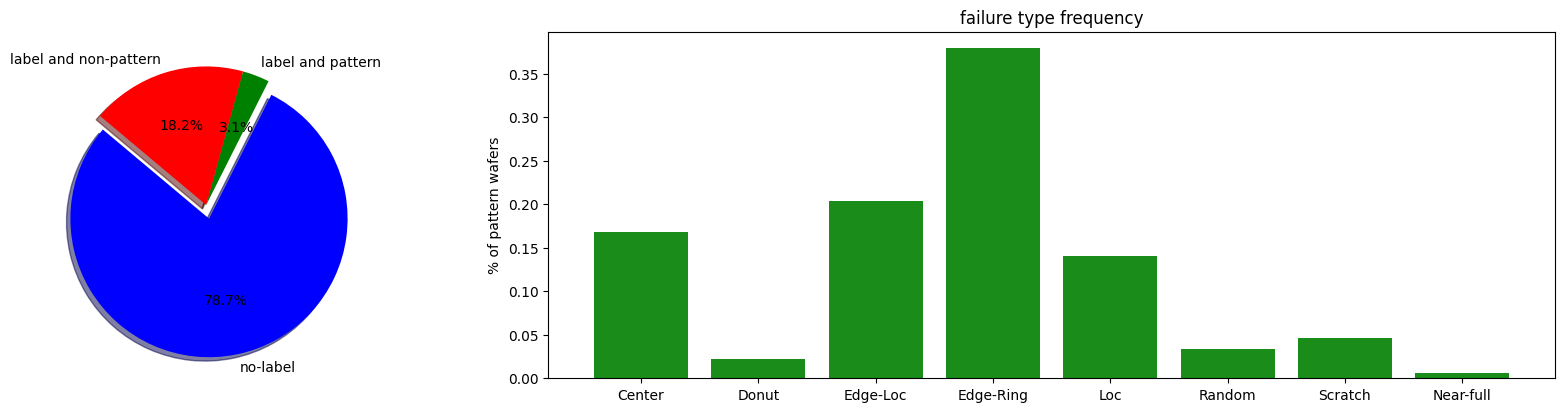

In [16]:
import matplotlib.pyplot as plt
%matplotlib inline

from matplotlib import gridspec
fig = plt.figure(figsize=(20, 4.5)) 
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 2.5]) 
ax1 = plt.subplot(gs[0])
ax2 = plt.subplot(gs[1])

no_wafers=[tol_wafers-df_withlabel.shape[0], df_withpattern.shape[0], df_nonpattern.shape[0]]

colors = ['blue', 'green', 'red']
explode = (0.1, 0, 0)  # explode 1st slice
labels = ['no-label','label and pattern','label and non-pattern']
ax1.pie(no_wafers, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True, startangle=140)

uni_pattern=np.unique(df_withpattern.failureNum, return_counts=True)
labels2 = ['','Center','Donut','Edge-Loc','Edge-Ring','Loc','Random','Scratch','Near-full']
ax2.bar(uni_pattern[0],uni_pattern[1]/df_withpattern.shape[0], color='green', align='center', alpha=0.9)
ax2.set_title("failure type frequency")
ax2.set_ylabel("% of pattern wafers")
ax2.set_xticklabels(labels2)

plt.show()

## PyTorch wafer-map models

The following cells port the TensorFlow autoencoder and CNN while preserving their layer sizes, losses, batch size, epochs, cross-validation procedure, and latent-space noise augmentation. Input wafer maps are expected in the original `(N, 26, 26, 3)` one-hot format.

In [17]:
import numpy as np
import time
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 30
BATCH_SIZE = 1024

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print(f"Training device: {torch.cuda.get_device_name(0)}")
else:
    print("Training device: CPU (enable a GPU accelerator in Kaggle for faster training)")
print(f"PyTorch CPU threads: {torch.get_num_threads()}")

Training device: Tesla T4
PyTorch CPU threads: 2


# autoencoder

In [18]:
class Autoencoder(nn.Module):
    """Encode and reconstruct one-hot 26x26 wafer maps.

    Tensor shapes use NCHW order inside the model: N is the batch size,
    C is the three one-hot wafer-state channels, and H/W are wafer rows/columns.
    The model input and reconstruction have shape `(N, 3, 26, 26)`; the
    encoded latent representation has shape `(N, 64, 13, 13)`.

    Example:
        model = Autoencoder()
    """

    def __init__(self):
        """Create the 3-channel encoder and decoder layers.

        Example:
            model = Autoencoder()
        """
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode="nearest"),
            nn.ConvTranspose2d(64, 3, kernel_size=3, padding=1),
            nn.Sigmoid(),
        )

    def encode(self, wafer_maps):
        """Convert NCHW wafer maps to 64-channel 13x13 latent maps.

        Args:
            wafer_maps: Float tensor `(N, 3, 26, 26)`; channels represent
                the one-hot wafer states and N is the batch size.

        Returns:
            Latent feature maps `(N, 64, 13, 13)`.

        Example:
            latent = model.encode(torch.zeros(1, 3, 26, 26))  # (1, 64, 13, 13)
        """
        return self.encoder(wafer_maps)

    def decode(self, latent_maps):
        """Reconstruct 26x26 wafer maps from latent representations.

        Args:
            latent_maps: Encoded tensor `(N, 64, 13, 13)`.

        Returns:
            Reconstructed wafer maps `(N, 3, 26, 26)` with values in `[0, 1]`.

        Example:
            reconstruction = model.decode(torch.zeros(1, 64, 13, 13))  # (1, 3, 26, 26)
        """
        return self.decoder(latent_maps)

    def forward(self, wafer_maps):
        """Encode and reconstruct a batch in one model call.

        Args:
            wafer_maps: Float tensor `(N, 3, 26, 26)` in NCHW order.

        Returns:
            Reconstructed tensor `(N, 3, 26, 26)`.

        Example:
            reconstruction = model(torch.zeros(1, 3, 26, 26))  # (1, 3, 26, 26)
        """
        return self.decode(self.encode(wafer_maps))


def _to_nchw(wafer_maps):
    """Convert a 4D wafer-map batch to contiguous float32 NCHW tensors.

    Args:
        wafer_maps: Wafer maps in NHWC shape `(N, 26, 26, 3)` or NCHW shape
            `(N, 3, 26, 26)`. N is the number of maps; the 3 channels encode
            the wafer-state categories.

    Returns:
        Contiguous float32 tensor `(N, 3, 26, 26)` in NCHW order.

    Example:
        maps = _to_nchw(np.zeros((4, 26, 26, 3)))  # torch.Size([4, 3, 26, 26])
    """
    wafer_maps = torch.as_tensor(wafer_maps, dtype=torch.float32)
    if wafer_maps.ndim != 4:
        raise ValueError("Wafer maps must be a 4D array.")
    if wafer_maps.shape[-1] == 3:
        wafer_maps = wafer_maps.permute(0, 3, 1, 2)
    return wafer_maps.contiguous()


def train_autoencoder(wafer_maps, epochs=EPOCHS, batch_size=BATCH_SIZE, device=DEVICE):
    """Train the autoencoder with Adam/MSE and report metrics every epoch.

    CUDA runs use mixed precision, channels-last convolution, pinned batches,
    and two data-loader workers. CPU runs keep a single-process data loader.

    Args:
        wafer_maps: NHWC `(N, 26, 26, 3)` or NCHW `(N, 3, 26, 26)` batch
            of wafer maps; N is the number of training maps and 3 channels
            encode the wafer-state categories.
        epochs: Number of complete passes over the training maps.
        batch_size: Number of maps in each shuffled training batch.
        device: PyTorch device used for model training.

    Returns:
        A tuple `(model, history)`. `model` is the trained `Autoencoder`
        (accepting `(N, 3, 26, 26)` and returning `(N, 3, 26, 26)`);
        `history` maps `"loss"` and `"epoch_time"` to lists of `epochs` floats.

    Example:
        autoencoder, history = train_autoencoder(wafer_maps, epochs=1, batch_size=8)
    """
    use_cuda = device.type == "cuda"
    training_maps = _to_nchw(wafer_maps)
    loader = DataLoader(
        TensorDataset(training_maps),
        batch_size=batch_size,
        shuffle=True,
        num_workers=2 if use_cuda else 0,
        pin_memory=use_cuda,
        persistent_workers=use_cuda,
    )
    model = Autoencoder().to(device)
    if use_cuda:
        model = model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters())
    loss_function = nn.MSELoss()
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    history = {"loss": [], "epoch_time": []}

    for epoch in range(epochs):
        epoch_started = time.perf_counter()
        model.train()
        total_loss = 0.0
        for (batch,) in loader:
            batch = batch.to(device, non_blocking=use_cuda)
            if use_cuda:
                batch = batch.to(memory_format=torch.channels_last)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_cuda):
                reconstruction = model(batch)
                loss = loss_function(reconstruction, batch)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * batch.size(0)

        epoch_loss = total_loss / len(loader.dataset)
        elapsed = time.perf_counter() - epoch_started
        history["loss"].append(epoch_loss)
        history["epoch_time"].append(elapsed)
        print(f"Epoch {epoch + 1:02d}/{epochs} - loss: {epoch_loss:.6f} - {elapsed:.1f}s")

    return model, history


def generate_augmented_data(model, wafer_maps, label, target_count=2000, batch_size=BATCH_SIZE, noise_scale=0.1, device=DEVICE):
    """Generate labeled maps by adding Gaussian noise to encoded wafers.

    Args:
        model: Trained `Autoencoder` used to encode and decode maps.
        wafer_maps: NHWC `(N, 26, 26, 3)` or NCHW `(N, 3, 26, 26)` maps
            from one defect class; N is the number of source maps.
        label: Scalar class label repeated for every generated map.
        target_count: Approximate number of maps to generate.
        batch_size: Present for API consistency; generation currently
            processes the source maps together and does not use this value.
        noise_scale: Standard deviation of the latent-space Gaussian noise.
        device: Device used for the encoder and decoder.

    Returns:
        A tuple `(generated_maps, generated_labels)`: maps have shape
        `(M, 26, 26, 3)` in NHWC order and labels have shape `(M, 1)`.
        M is the source-map count multiplied by
        `(target_count // N) + 1`, so the generated count is at least
        `target_count` when `target_count` is non-negative.

    Example:
        generated_maps, generated_labels = generate_augmented_data(
            autoencoder, class_maps, "Center", target_count=2000
        )
    """
    wafer_tensor = _to_nchw(wafer_maps).to(device)
    if len(wafer_tensor) == 0:
        raise ValueError("At least one wafer map is required for augmentation.")

    model = model.to(device)
    model.eval()
    generated_batches = []
    repetitions = (target_count // len(wafer_tensor)) + 1
    with torch.no_grad():
        for _ in range(repetitions):
            latent_maps = model.encode(wafer_tensor)
            noisy_latent_maps = latent_maps + torch.randn_like(latent_maps) * noise_scale
            generated = model.decode(noisy_latent_maps)
            generated_batches.append(generated.cpu())

    generated_maps = torch.cat(generated_batches, dim=0)[:repetitions * len(wafer_tensor)]
    generated_maps = generated_maps.permute(0, 2, 3, 1).numpy()
    generated_labels = np.full((len(generated_maps), 1), label)
    return generated_maps, generated_labels

# CNN 

In [61]:
class CNN(nn.Module):
    """Classify 26x26 wafer maps into defect categories.

    Model inputs use NCHW shape `(N, 3, 26, 26)`: N is batch size, the
    three channels are one-hot wafer states, and H/W are wafer rows/columns.
    The output is `(N, number_of_classes)` raw class logits, one row per map.

    Example:
        classifier = CNN(number_of_classes=9)
    """

    def __init__(self, number_of_classes=9):
        """Build the three-convolution classifier and output layer.

        Args:
            number_of_classes: Number of defect categories to predict.

        Example:
            classifier = CNN(number_of_classes=9)
        """
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(128 * 26 * 26, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, number_of_classes),
        )

    def forward(self, wafer_maps):
        """Return one raw class score (logit) per category and wafer.

        Args:
            wafer_maps: Float tensor `(N, 3, 26, 26)` in NCHW order.

        Returns:
            Logit tensor `(N, number_of_classes)`; each row contains one
            unnormalized score for each defect category.

        Example:
            scores = classifier(torch.zeros(2, 3, 26, 26))  # torch.Size([2, 9])
        """
        return self.network(wafer_maps)


def _class_indices(labels):
    """Convert sparse or one-hot labels to integer class indices.

    Args:
        labels: Sparse labels `(N,)` or one-hot labels `(N, C)`, where N is
            the number of maps and C is the number of classes.

    Returns:
        Long tensor `(N,)` containing one class index per map.

    Example:
        indices = _class_indices(torch.tensor([[0, 1, 0], [1, 0, 0]]))  # [1, 0]
    """
    labels = torch.as_tensor(labels)
    if labels.ndim > 1:
        labels = labels.argmax(dim=1)
    return labels.to(dtype=torch.long)


def plot_confusion_matrix(true_labels, predicted_labels, class_names=None, normalize=True, title="Confusion matrix"):
    """Plot a confusion matrix heatmap (rows = true class, columns = predicted class).

    Args:
        true_labels: Class indices `(N,)` as a tensor or array.
        predicted_labels: Predicted class indices `(N,)`, same length as `true_labels`.
        class_names: Optional list of C class names for the axis ticks. Defaults to
            the 9 wafer defect names in `mapping_type` order when C == 9.
        normalize: If True, each row is divided by its true-class count (recall per class).
        title: Figure title.

    Returns:
        The `(C, C)` numpy confusion-matrix counts (unnormalized).

    Example:
        cm = plot_confusion_matrix(y_true, y_pred, normalize=True)
    """
    from sklearn.metrics import confusion_matrix

    true_labels = torch.as_tensor(true_labels).cpu().numpy()
    predicted_labels = torch.as_tensor(predicted_labels).cpu().numpy()
    if class_names is None:
        default_names = ["Center", "Donut", "Edge-Loc", "Edge-Ring", "Loc", "Random", "Scratch", "Near-full", "none"]
        class_names = default_names if int(max(true_labels.max(), predicted_labels.max())) < len(default_names) else None
    number_of_classes = len(class_names) if class_names is not None else int(max(true_labels.max(), predicted_labels.max())) + 1
    class_indices = np.arange(number_of_classes)
    counts = confusion_matrix(true_labels, predicted_labels, labels=class_indices)
    display = counts.astype(float)
    if normalize:
        display = display / np.maximum(display.sum(axis=1, keepdims=True), 1)

    figure, axis = plt.subplots(figsize=(8, 7))
    image = axis.imshow(display, interpolation="nearest", cmap="Blues")
    figure.colorbar(image, ax=axis)
    tick_labels = class_names if class_names is not None else class_indices
    axis.set(
        xticks=class_indices, yticks=class_indices,
        xticklabels=tick_labels, yticklabels=tick_labels,
        xlabel="Predicted label", ylabel="True label", title=title,
    )
    plt.setp(axis.get_xticklabels(), rotation=45, ha="right")
    threshold = display.max() / 2.0
    for row in range(number_of_classes):
        for column in range(number_of_classes):
            text = f"{display[row, column]:.2f}" if normalize else str(counts[row, column])
            axis.text(column, row, text, ha="center", va="center",
                      color="white" if display[row, column] > threshold else "black")
    figure.tight_layout()
    plt.show()
    return counts


def _evaluate_cnn(model, wafer_maps, labels, loss_function, device, batch_size=BATCH_SIZE, plot_confusion=False, class_names=None):
    """Measure loss, accuracy, and class metrics without updating model weights.

    Args:
        model: CNN returning logits `(N, C)` for input maps `(N, 3, 26, 26)`.
        wafer_maps: NCHW float tensor `(N, 3, 26, 26)`.
        labels: Long class-index tensor `(N,)` with values in `[0, C)`.
        loss_function: Loss accepting logits `(B, C)` and class indices `(B,)`.
        device: Device on which evaluation batches are run.
        batch_size: Number of maps processed per evaluation batch.
        plot_confusion: If True, call `plot_confusion_matrix` on all N predictions.
        class_names: Optional class names forwarded to `plot_confusion_matrix`.

    Returns:
        Pair `(mean_loss, accuracy)`, both Python floats; accuracy is the
        fraction of the N maps whose predicted class matches its label.
        Per-class precision, recall, and F1, plus their macro averages, are
        printed for the evaluated dataset.

    Example:
        loss, accuracy = _evaluate_cnn(
            classifier, maps, labels, nn.CrossEntropyLoss(), DEVICE
        )
    """
    use_cuda = device.type == "cuda"
    loader = DataLoader(
        TensorDataset(wafer_maps, labels),
        batch_size=batch_size,
        num_workers=2 if use_cuda else 0,
        pin_memory=use_cuda,
        persistent_workers=use_cuda,
    )
    model.eval()
    total_loss = 0.0
    correct = 0
    all_predictions = []
    confusion_counts = None
    with torch.no_grad():
        for batch_maps, batch_labels in loader:
            batch_maps = batch_maps.to(device, non_blocking=use_cuda)
            batch_labels = batch_labels.to(device, non_blocking=use_cuda)
            if use_cuda:
                batch_maps = batch_maps.to(memory_format=torch.channels_last)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_cuda):
                logits = model(batch_maps)
                loss = loss_function(logits, batch_labels)
            predictions = logits.argmax(dim=1)
            number_of_classes = logits.size(1)
            cpu_predictions = predictions.cpu()
            cpu_labels = batch_labels.cpu()
            batch_counts = torch.bincount(
                cpu_labels * number_of_classes + cpu_predictions,
                minlength=number_of_classes ** 2,
            ).reshape(number_of_classes, number_of_classes)
            if confusion_counts is None:
                confusion_counts = torch.zeros_like(batch_counts)
            confusion_counts += batch_counts
            total_loss += loss.item() * batch_maps.size(0)
            correct += (predictions == batch_labels).sum().item()
            if plot_confusion:
                all_predictions.append(cpu_predictions)
    true_positive = confusion_counts.diag().to(torch.float32)
    predicted_count = confusion_counts.sum(dim=0).to(torch.float32)
    actual_count = confusion_counts.sum(dim=1).to(torch.float32)
    precision = torch.where(predicted_count > 0, true_positive / predicted_count.clamp_min(1), 0)
    recall = torch.where(actual_count > 0, true_positive / actual_count.clamp_min(1), 0)
    f1_scores = torch.where(
        precision + recall > 0,
        2 * precision * recall / (precision + recall).clamp_min(1e-12),
        0,
    )
    print("Per-class precision, recall, and F1:")
    for class_index in range(number_of_classes):
        class_label = class_names[class_index] if class_names is not None else f"Class {class_index}"
        print(
            f"  {class_label}: precision={precision[class_index].item():.4f}, "
            f"recall={recall[class_index].item():.4f}, F1={f1_scores[class_index].item():.4f}"
        )
    print(
        f"Macro precision: {precision.mean().item():.4f} - "
        f"Macro recall: {recall.mean().item():.4f} - "
        f"Mean F1 (macro): {f1_scores.mean().item():.4f}"
    )
    if plot_confusion:
        plot_confusion_matrix(labels, torch.cat(all_predictions), class_names, title="Evaluation confusion matrix")
    return total_loss / len(labels), correct / len(labels)


def _fit_cnn(model, training_maps, training_labels, validation_maps, validation_labels, class_weights, epochs, batch_size, device, phase="Training"):
    """Fit one CNN with mixed precision on CUDA and log each epoch.

    Args:
        model: CNN to train, producing logits `(B, C)` from maps `(B, 3, 26, 26)`.
        training_maps: NCHW float tensor `(N_train, 3, 26, 26)`.
        training_labels: Long class-index tensor `(N_train,)`.
        validation_maps: NCHW float tensor `(N_val, 3, 26, 26)`.
        validation_labels: Long class-index tensor `(N_val,)`.
        class_weights: (num_classes,) List of weights for each class to handle class imbalance.
        epochs: Number of complete passes through the training set.
        batch_size: Number of maps in each training/evaluation batch.
        device: Device used for model training and evaluation.
        phase: Text prefix used in the epoch progress messages.

    Returns:
        Pair `(model, history)`. `history` contains per-epoch float lists
        for `loss`, `accuracy`, `val_loss`, `val_accuracy`, and `epoch_time`.

    Example:
        fitted_model, history = _fit_cnn(
            CNN(), train_maps, train_labels, val_maps, val_labels, class_weights=class_weights,
            epochs=1, batch_size=8, device=DEVICE
        )
    """
    use_cuda = device.type == "cuda"
    model = model.to(device)
    if use_cuda:
        model = model.to(memory_format=torch.channels_last)
    optimizer = torch.optim.Adam(model.parameters())
    loss_function = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=device) if class_weights is not None else None)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    loader = DataLoader(
        TensorDataset(training_maps, training_labels),
        batch_size=batch_size,
        shuffle=True,
        num_workers=2 if use_cuda else 0,
        pin_memory=use_cuda,
        persistent_workers=use_cuda,
    )
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [], "epoch_time": []}

    for epoch in range(epochs):
        epoch_started = time.perf_counter()
        model.train()
        total_loss = 0.0
        correct = 0
        for batch_maps, batch_labels in loader:
            batch_maps = batch_maps.to(device, non_blocking=use_cuda)
            batch_labels = batch_labels.to(device, non_blocking=use_cuda)
            if use_cuda:
                batch_maps = batch_maps.to(memory_format=torch.channels_last)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_cuda):
                logits = model(batch_maps)
                loss = loss_function(logits, batch_labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += loss.item() * batch_maps.size(0)
            correct += (logits.argmax(dim=1) == batch_labels).sum().item()

        validation_loss, validation_accuracy = _evaluate_cnn(
            model, validation_maps, validation_labels, loss_function, device, batch_size
        )
        epoch_loss = total_loss / len(training_labels)
        epoch_accuracy = correct / len(training_labels)
        elapsed = time.perf_counter() - epoch_started
        history["loss"].append(epoch_loss)
        history["accuracy"].append(epoch_accuracy)
        history["val_loss"].append(validation_loss)
        history["val_accuracy"].append(validation_accuracy)
        history["epoch_time"].append(elapsed)
        print(
            f"{phase} - Epoch {epoch + 1:02d}/{epochs} - "
            f"loss: {epoch_loss:.4f} - accuracy: {epoch_accuracy:.4f} - "
            f"val_loss: {validation_loss:.4f} - val_accuracy: {validation_accuracy:.4f} - "
            f"{elapsed:.1f}s"
        )

    return model, history


def train_cnn(x_train, y_train, x_validation, y_validation, class_weights=None, epochs=EPOCHS, batch_size=BATCH_SIZE, device=DEVICE):
    """Run shuffled 3-fold cross-validation, then fit on all training data.

    Args:
        x_train: NHWC `(N_train, 26, 26, 3)` or NCHW
            `(N_train, 3, 26, 26)` training maps.
        y_train: Sparse labels `(N_train,)` or one-hot labels `(N_train, C)`.
        x_validation: NHWC `(N_val, 26, 26, 3)` or NCHW
            `(N_val, 3, 26, 26)` held-out validation maps.
        y_validation: Sparse labels `(N_val,)` or one-hot labels `(N_val, C)`.
        class_weights: (num_classes,) List of weights for each class to handle class imbalance.
        epochs: Epochs used in each fold and in the final fit.
        batch_size: Number of maps per training batch.
        device: PyTorch device used for model training.
        
    Returns:
        Tuple `(model, history, fold_scores)`. The final model accepts maps
        `(N, 3, 26, 26)` and returns logits `(N, C)`. `history` contains
        five per-epoch float lists (`loss`, `accuracy`, `val_loss`,
        `val_accuracy`, `epoch_time`); `fold_scores` is a list of 3 floats.

    Example:
        classifier, history, fold_scores = train_cnn(
            x_train, y_train, x_validation, y_validation, class_weights=class_weights,
            epochs=30, batch_size=1024
        )
        print(history["val_accuracy"][-1])
    """
    training_maps = _to_nchw(x_train)
    training_labels = _class_indices(y_train)
    validation_maps = _to_nchw(x_validation)
    validation_labels = _class_indices(y_validation)

    fold_splitter = KFold(n_splits=3, shuffle=True, random_state=2019)
    cross_validation_scores = []
    for fold_number, (train_indices, validation_indices) in enumerate(
        fold_splitter.split(np.arange(len(training_maps))), start=1
    ):
        train_indices = torch.as_tensor(train_indices, dtype=torch.long)
        validation_indices = torch.as_tensor(validation_indices, dtype=torch.long)
        _, fold_history = _fit_cnn(
            CNN(),
            training_maps[train_indices],
            training_labels[train_indices],
            training_maps[validation_indices],
            training_labels[validation_indices],
            class_weights,
            epochs,
            batch_size,
            device,
            phase=f"CV fold {fold_number}/3",
        )
        cross_validation_scores.append(fold_history["val_accuracy"][-1])

    print("Simple CNN Cross validation score : {:.4f}".format(np.mean(cross_validation_scores)))
    model, history = _fit_cnn(
        CNN(),
        training_maps,
        training_labels,
        validation_maps,
        validation_labels,
        class_weights,
        epochs,
        batch_size,
        device,
        phase="Final fit",
    )
    print("Testing Accuracy: {:.4f}".format(history["val_accuracy"][-1]))
    return model, history, cross_validation_scores

# data prep


In [20]:
import numpy as np
from skimage.transform import resize
from joblib import Parallel, delayed

def resize_single_wafer(wafer_map, target_shape=(26, 26)):
    """Resizes a single wafer map using nearest-neighbor interpolation."""
    # order=0 strictly preserves the integer categories (0, 1, 2)
    resized = resize(wafer_map, target_shape, order=0, preserve_range=True)
    return resized.astype(np.uint8)

def bulk_resize_wafers(wafer_list, target_shape=(26, 26), n_jobs=-1):
    """
    Bulk resizes a collection of wafer maps of varying dimensions to a fixed shape.
    
    Parameters:
    -----------
    wafer_list : list or array-like
        A list or series containing 2D numpy arrays of different sizes.
    target_shape : tuple, optional
        The desired output dimensions, by default (26, 26).
    n_jobs : int, optional
        Number of CPU cores to use. -1 uses all available cores.
        
    Returns:
    --------
    numpy.ndarray
        A unified 3D numpy array of shape (N_samples, target_shape[0], target_shape[1])
    """
    print(f"🚀 Processing {len(wafer_list)} wafers using {n_jobs if n_jobs != -1 else 'all'} CPU cores...")
    
    # Run the resizing function in parallel across CPU cores
    resized_list = Parallel(n_jobs=n_jobs)(
        delayed(resize_single_wafer)(wafer, target_shape) for wafer in wafer_list
    )
    
    # Stack the list of 2D arrays into a single, clean 3D numpy array
    return np.stack(resized_list, axis=0)


In [21]:
x = df_withlabel['waferMap'].to_list()
y = df_withlabel['failureType'].to_list()

In [22]:
len(x)

172950

In [23]:
resized = bulk_resize_wafers(x, (26,26),-1)

🚀 Processing 172950 wafers using all CPU cores...


In [24]:
resized.shape

(172950, 26, 26)

In [25]:
y = np.array(y).reshape((-1, 1))

In [26]:
y.shape

(172950, 1)

In [27]:
x = resized

In [83]:
print("x shape:", x.shape)
print("y shape:", y.shape)

x shape: (172950, 26, 26, 1)
y shape: (172950, 1)


In [84]:
x= x.reshape(-1, 26,26)

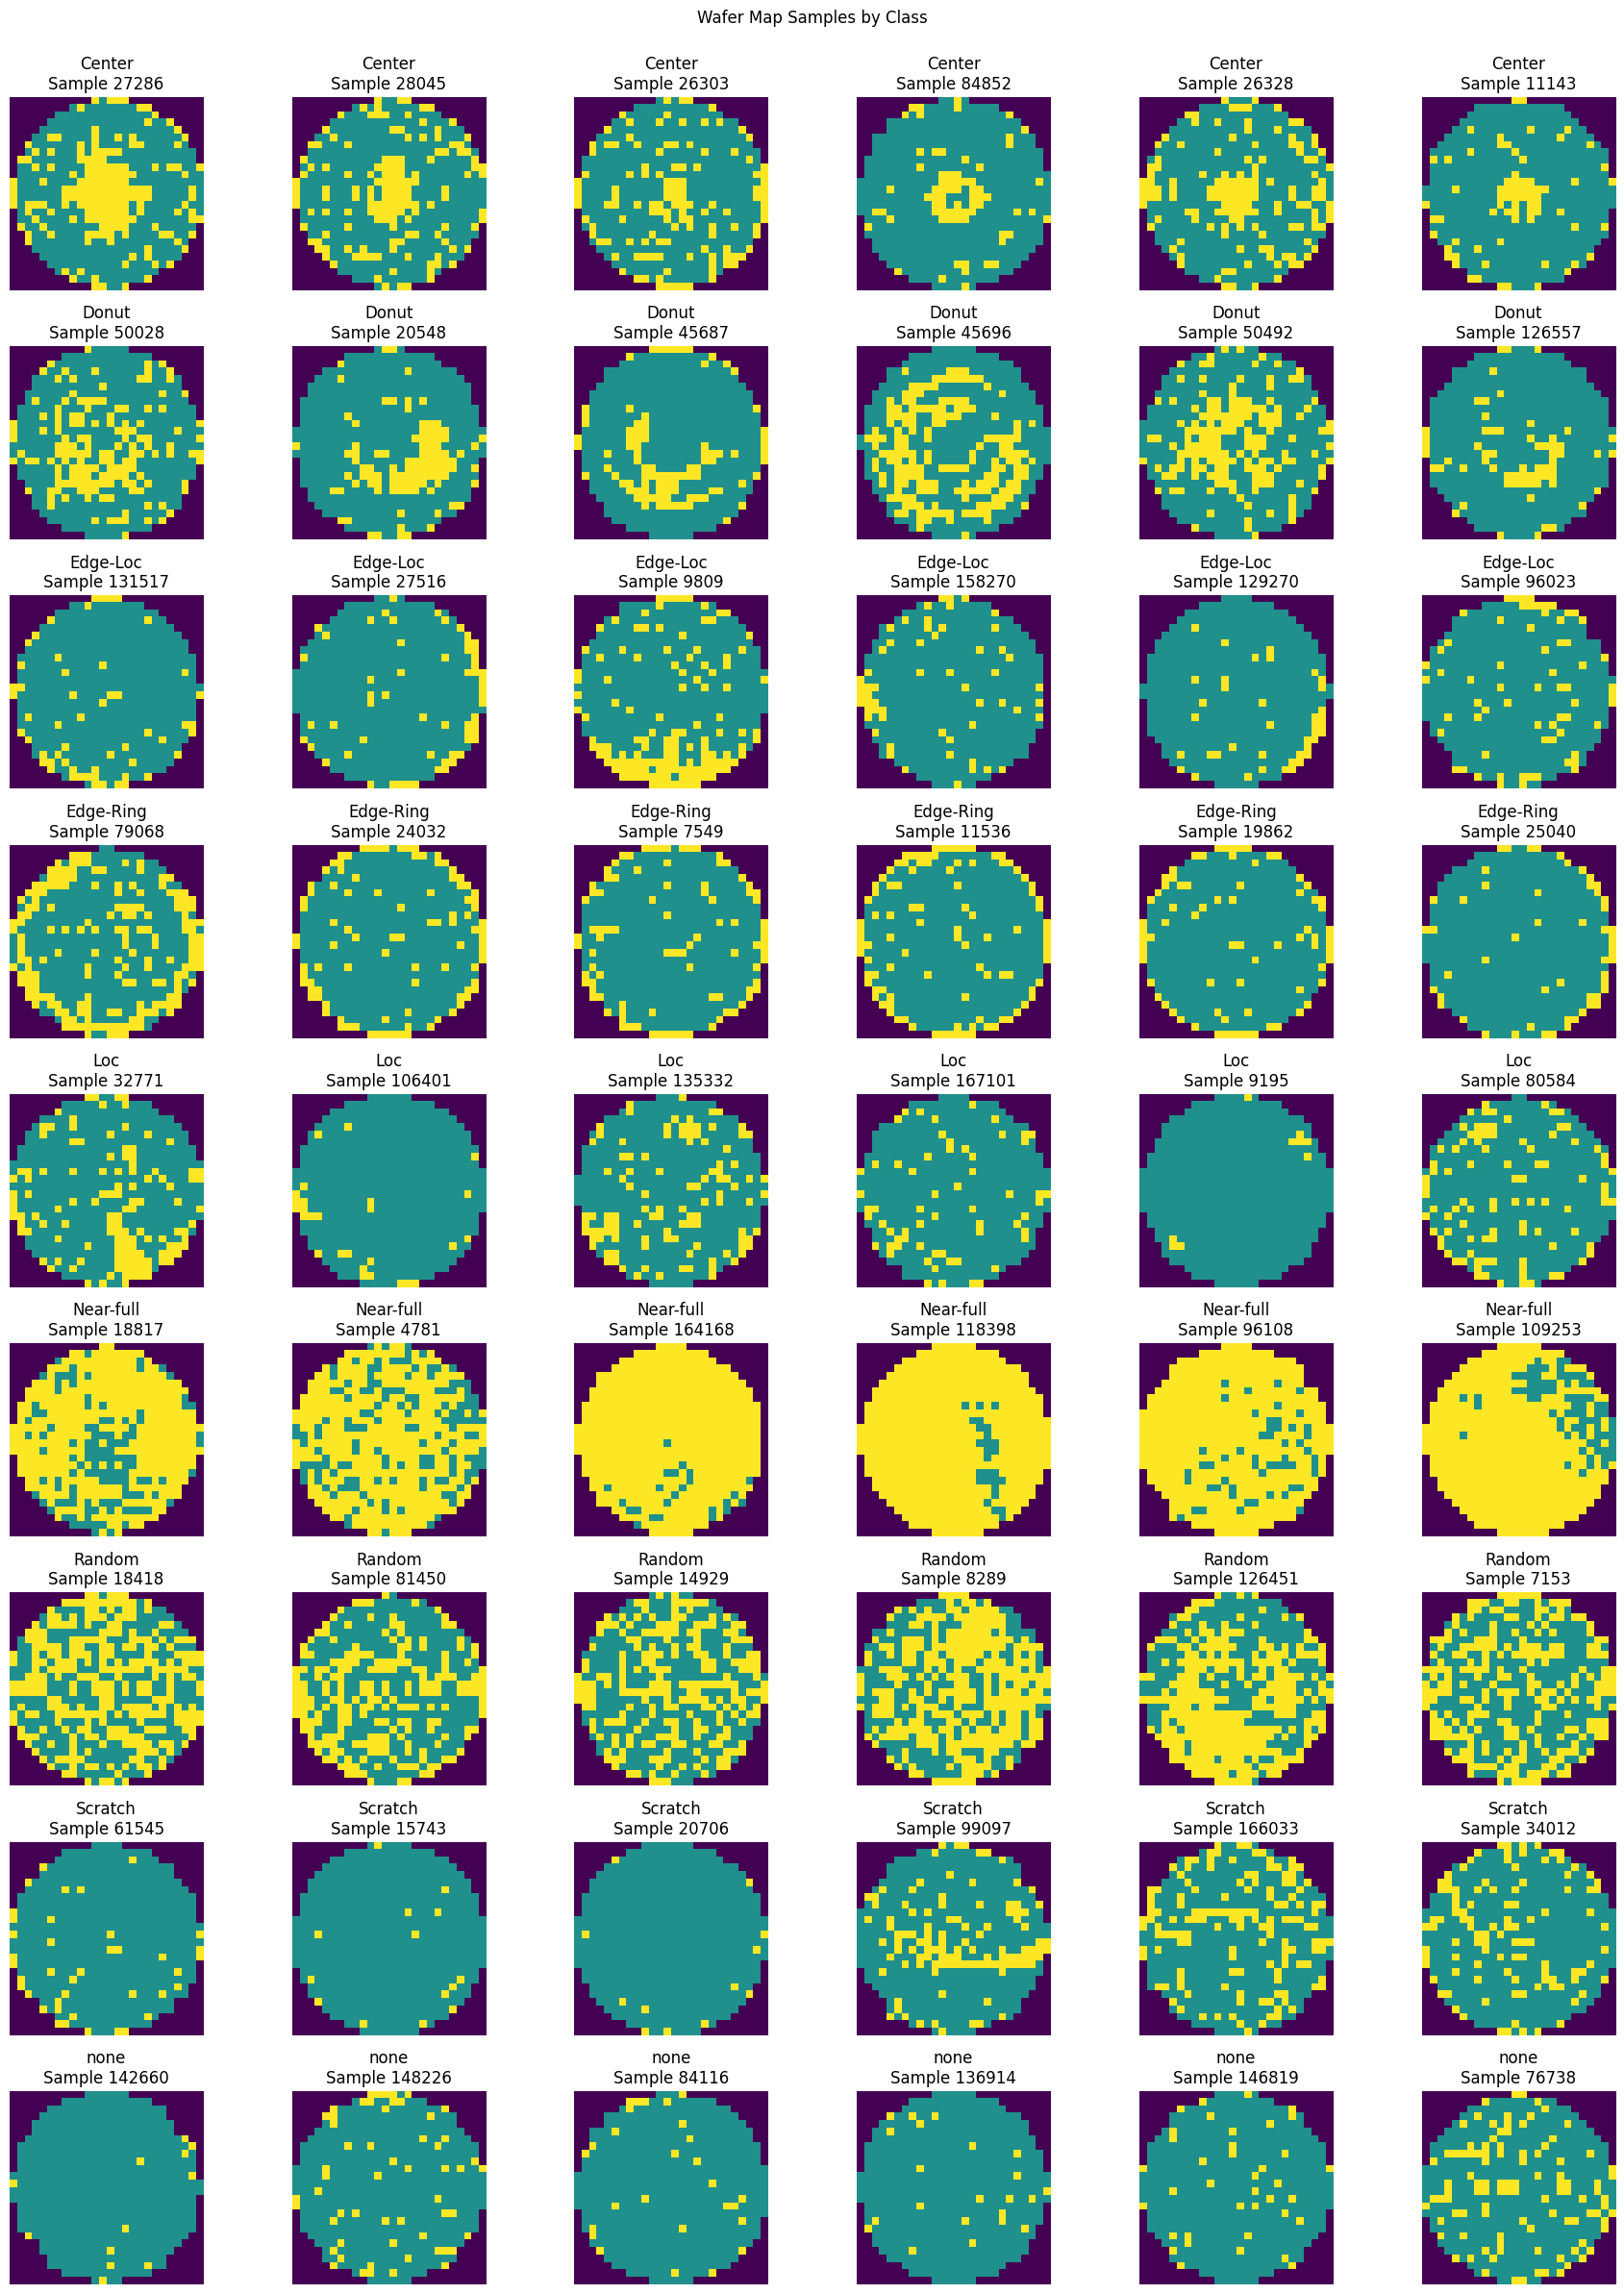

In [103]:
def show_images_by_class(images, labels, samples_per_class=6, seed=42):
    """Plot a random sample of wafer maps for every class with labels.

    Args:
        images: Wafer maps with shape (N, H, W) or (N, H, W, C).
        labels: Class labels as values or one-hot encoded rows.
        samples_per_class: Maximum number of maps to show for each class.
        seed: Random seed so the displayed examples are reproducible.

    Returns:
        The Matplotlib figure and 2D axes array.

    Example:
        fig, axes = show_images_by_class(x, y, samples_per_class=3)
    """
    images = np.asarray(images)
    labels = np.asarray(labels)

    if labels.ndim == 2 and labels.shape[1] > 1:
        labels = labels.argmax(axis=1)
    else:
        labels = labels.reshape(-1)

    if len(images) != len(labels):
        raise ValueError("The number of images must match the number of labels.")
    if samples_per_class < 1:
        raise ValueError("samples_per_class must be at least 1.")

    classes = np.unique(labels)
    figure, axes = plt.subplots(
        len(classes),
        samples_per_class,
        figsize=(3 * samples_per_class, 2.7 * len(classes)),
        squeeze=False,
    )
    rng = np.random.default_rng(seed)

    for row, class_label in enumerate(classes):
        class_indices = np.flatnonzero(labels == class_label)
        selected_indices = rng.choice(
            class_indices,
            size=min(samples_per_class, len(class_indices)),
            replace=False,
        )

        for column, axis in enumerate(axes[row]):
            if column < len(selected_indices):
                image_index = selected_indices[column]
                axis.imshow(images[image_index].squeeze(), cmap="viridis", interpolation="nearest")
                axis.set_title(f"{class_label}\nSample {image_index}")
            axis.axis("off")

    figure.suptitle("Wafer Map Samples by Class")
    figure.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()
    return figure, axes


fig, axes = show_images_by_class(x, y, samples_per_class=6)

In [30]:
faulty_case = np.unique(y)
print(f"faulty cases: {faulty_case}")

faulty cases: ['Center' 'Donut' 'Edge-Loc' 'Edge-Ring' 'Loc' 'Near-full' 'Random'
 'Scratch' 'none']


In [31]:
x = x.reshape(-1,26,26,1) # NHWC format

In [32]:
for f in faulty_case:
        print('{}:{}'.format(f, np.sum(y==f)))

Center:4294
Donut:555
Edge-Loc:5189
Edge-Ring:9680
Loc:3593
Near-full:149
Random:866
Scratch:1193
none:147431


In [33]:
indices = x.squeeze(axis=-1).astype(int)
new_x = np.eye(3)[indices]


In [34]:
new_y =y
for i,l in enumerate(faulty_case):
        new_y[new_y==l] = i
# one-hot encoding

new_y = to_categorical(new_y)

In [35]:
print("new_x shape:", new_x.shape)
print("new_y shape:", new_y.shape)

new_x shape: (172950, 26, 26, 3)
new_y shape: (172950, 9)


In [36]:
# splitting the dataset early into training and testing sets before any data augmentation
x_train, x_test, y_train, y_test = train_test_split(new_x, new_y, test_size=0.2, random_state=2026)
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: (138360, 26, 26, 3)
x_test shape: (34590, 26, 26, 3)
y_train shape: (138360, 9)
y_test shape: (34590, 9)


In [37]:
print("Faulty case counts in training  vs testing set:")
for i,f in enumerate(faulty_case):
        print('{}: {} : {}'.format(f,np.sum(y_train[:,i]==1),np.sum(y_test[:,i]==1)))
print(f"total wafers: {y_train.shape[0]} : {y_test.shape[0]}")
# print("Faulty case counts in testing set:")
# for i,f in enumerate(faulty_case):
#         print('{}:{}'.format(f,np.sum(y_test[:,i]==1)))

Faulty case counts in training  vs testing set:
Center: 3459 : 835
Donut: 425 : 130
Edge-Loc: 4118 : 1071
Edge-Ring: 7781 : 1899
Loc: 2913 : 680
Near-full: 117 : 32
Random: 686 : 180
Scratch: 942 : 251
none: 117919 : 29512
total wafers: 138360 : 34590


In [38]:
x_train.shape, y_train.shape, new_x.shape, new_y.shape, x.shape, y.shape

((138360, 26, 26, 3),
 (138360, 9),
 (172950, 26, 26, 3),
 (172950, 9),
 (172950, 26, 26, 1),
 (172950, 1))

In [39]:
def rebalance_classes(x_maps, y_onehot, samples_per_class=3000, random_state=2026):
    """Cap every class at `samples_per_class` maps by undersampling; never add samples.

    Classes with more than `samples_per_class` maps are randomly reduced to that
    count without replacement. Classes with fewer maps are kept unchanged.
    The result is shuffled.

    Args:
        x_maps: Wafer maps `(N, 26, 26, 3)`.
        y_onehot: One-hot labels `(N, C)`.
        samples_per_class: Maximum number of maps kept for each class.
        random_state: Seed for reproducible sampling.

    Returns:
        `(x_rebalanced, y_rebalanced)` with shapes `(M, 26, 26, 3)` and `(M, C)`,
        where `M = sum(min(class_count, samples_per_class))`.

    Example:
        x_rebalanced, y_rebalanced = rebalance_classes(x_train, y_train, 3000)
    """
    rng = np.random.default_rng(random_state)
    class_ids = np.argmax(y_onehot, axis=1)
    selected = []
    for class_id in range(y_onehot.shape[1]):
        class_indices = np.flatnonzero(class_ids == class_id)
        if len(class_indices) > samples_per_class:
            class_indices = rng.choice(class_indices, size=samples_per_class, replace=False)
        selected.append(class_indices)
    selected = rng.permutation(np.concatenate(selected))
    return x_maps[selected], y_onehot[selected]


x_rebalanced, y_rebalanced = rebalance_classes(x_train, y_train)
print(f"x_rebalanced shape: {x_rebalanced.shape}")
print(f"y_rebalanced shape: {y_rebalanced.shape}")
for i, f in enumerate(faulty_case):
    print('{}: {} -> {}'.format(f, np.sum(y_train[:, i] == 1), np.sum(y_rebalanced[:, i] == 1)))

x_rebalanced shape: (17083, 26, 26, 3)
y_rebalanced shape: (17083, 9)
Center: 3459 -> 3000
Donut: 425 -> 425
Edge-Loc: 4118 -> 3000
Edge-Ring: 7781 -> 3000
Loc: 2913 -> 2913
Near-full: 117 -> 117
Random: 686 -> 686
Scratch: 942 -> 942
none: 117919 -> 3000


# Autoencoder training and synthetic wafermaps generation

In [40]:
ae, history = train_autoencoder(x_train)

Epoch 01/30 - loss: 0.049374 - 6.9s
Epoch 02/30 - loss: 0.014371 - 2.9s
Epoch 03/30 - loss: 0.008064 - 2.9s
Epoch 04/30 - loss: 0.005610 - 2.9s
Epoch 05/30 - loss: 0.004182 - 3.9s
Epoch 06/30 - loss: 0.003269 - 2.9s
Epoch 07/30 - loss: 0.002656 - 2.9s
Epoch 08/30 - loss: 0.002229 - 2.9s
Epoch 09/30 - loss: 0.001923 - 2.9s
Epoch 10/30 - loss: 0.001689 - 2.9s
Epoch 11/30 - loss: 0.001504 - 2.9s
Epoch 12/30 - loss: 0.001354 - 2.9s
Epoch 13/30 - loss: 0.001225 - 2.9s
Epoch 14/30 - loss: 0.001081 - 2.9s
Epoch 15/30 - loss: 0.000976 - 2.9s
Epoch 16/30 - loss: 0.000890 - 3.0s
Epoch 17/30 - loss: 0.000822 - 3.0s
Epoch 18/30 - loss: 0.000765 - 3.0s
Epoch 19/30 - loss: 0.000713 - 3.0s
Epoch 20/30 - loss: 0.000666 - 3.0s
Epoch 21/30 - loss: 0.000627 - 3.0s
Epoch 22/30 - loss: 0.000591 - 3.0s
Epoch 23/30 - loss: 0.000557 - 3.0s
Epoch 24/30 - loss: 0.000534 - 3.6s
Epoch 25/30 - loss: 0.000504 - 3.0s
Epoch 26/30 - loss: 0.000483 - 3.0s
Epoch 27/30 - loss: 0.000460 - 3.0s
Epoch 28/30 - loss: 0.000440

In [41]:
np.where(y_train[:,0]==1)[0].shape

(3459,)

In [42]:
gen_x, gen_y = generate_augmented_data(ae, x_train[np.where(y_train[:,0]==1)[0]], "Center", target_count=100000)

In [43]:
gen_y

array([['Center'],
       ['Center'],
       ['Center'],
       ...,
       ['Center'],
       ['Center'],
       ['Center']], dtype='<U6')

In [44]:
gen_y[gen_y=="Center"]=1

In [45]:
to_categorical(gen_y, num_classes=len(faulty_case))

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.]])

In [46]:
print("gen_x shape:", gen_x.shape)
print("gen_y shape:", gen_y.shape)

gen_x shape: (100311, 26, 26, 3)
gen_y shape: (100311, 1)


In [47]:
import gc
# del gen_x
# del gen_y
del df
del df_nonpattern
gc.collect()

54

In [48]:
import gc

# 1. Ensure you only have your filtered data (the ~17% labeled maps)
# Let's assume you saved it as 'labeled_df'

# 2. Explicitly delete the giant original variable
if 'df' in locals():
    del df
if 'df_nonpattern' in locals():
    del df_nonpattern

# 3. Force Python's Garbage Collector to free up the RAM
gc.collect()


0

In [49]:
x_train.shape

(138360, 26, 26, 3)

In [50]:
for i,f in enumerate(faulty_case):
        if f == "none":
                continue

        gen_x, gen_y = generate_augmented_data(ae, x_train[np.where(y_train[:,i]==1)[0]], f, target_count=10000)
        gen_y[gen_y==f]=i
        one_hot_gen_y = to_categorical(gen_y, num_classes=len(faulty_case))
        x_train = np.concatenate((x_train, gen_x), axis=0)
        y_train = np.concatenate((y_train, one_hot_gen_y), axis=0)
print("shape of the augmented training data:")
print("shape of x_train:", x_train.shape)
print("shape of y_train:", y_train.shape)

shape of the augmented training data:
shape of x_train: (229219, 26, 26, 3)
shape of y_train: (229219, 9)


In [51]:
print("Faulty case counts in training  vs testing set after augmenting the training set:")
for i,f in enumerate(faulty_case):
        print('{}: {} : {}'.format(f,np.sum(y_train[:,i]==1),np.sum(y_test[:,i]==1)))
print(f"total wafers: {y_train.shape[0]} : {y_test.shape[0]}")

Faulty case counts in training  vs testing set after augmenting the training set:
Center: 13836 : 835
Donut: 10625 : 130
Edge-Loc: 16472 : 1071
Edge-Ring: 23343 : 1899
Loc: 14565 : 680
Near-full: 10179 : 32
Random: 10976 : 180
Scratch: 11304 : 251
none: 117919 : 29512
total wafers: 229219 : 34590


# CNN training and evaluation

In [56]:
class_counts = []
for i,f in enumerate(faulty_case):
        class_counts.append(np.sum(y_train[:,i] == 1))
print(class_counts)

[np.int64(13836), np.int64(10625), np.int64(16472), np.int64(23343), np.int64(14565), np.int64(10179), np.int64(10976), np.int64(11304), np.int64(117919)]


In [57]:
total_samples = sum(class_counts)
class_weights = [total_samples / count for count in class_counts]
print(class_weights)

[np.float64(16.566854582249206), np.float64(21.57355294117647), np.float64(13.915675084992715), np.float64(9.819603307201302), np.float64(15.737658771026434), np.float64(22.518813242951175), np.float64(20.88365524781341), np.float64(20.27768931351734), np.float64(1.9438682485434917)]


In [62]:
classifier, history, fold_scores = train_cnn(
            x_train, y_train, x_test, y_test, class_weights=class_weights
        )
print(history["val_accuracy"][-1])

Per-class precision, recall, and F1:
  Class 0: precision=0.8023, recall=0.9375, F1=0.8646
  Class 1: precision=0.9928, recall=0.8627, F1=0.9232
  Class 2: precision=0.8475, recall=0.6833, F1=0.7566
  Class 3: precision=0.9479, recall=0.9661, F1=0.9569
  Class 4: precision=0.6421, recall=0.7237, F1=0.6805
  Class 5: precision=0.9966, recall=1.0000, F1=0.9983
  Class 6: precision=0.8964, recall=0.9745, F1=0.9338
  Class 7: precision=0.5645, recall=0.3248, F1=0.4124
  Class 8: precision=0.9136, recall=0.9425, F1=0.9278
Macro precision: 0.8449 - Macro recall: 0.8239 - Mean F1 (macro): 0.8282
CV fold 1/3 - Epoch 01/30 - loss: 0.6796 - accuracy: 0.6725 - val_loss: 0.3989 - val_accuracy: 0.8819 - 13.4s
Per-class precision, recall, and F1:
  Class 0: precision=0.7996, recall=0.9620, F1=0.8733
  Class 1: precision=0.9952, recall=1.0000, F1=0.9976
  Class 2: precision=0.7926, recall=0.8139, F1=0.8031
  Class 3: precision=0.9434, recall=0.9852, F1=0.9639
  Class 4: precision=0.7303, recall=0.785

In [63]:
x_train.shape, y_train.shape

((229219, 26, 26, 3), (229219, 9))

In [71]:
x_train_low_none, y_train_low_none = zip(*[ (x_train[idx], y_train[idx]) for idx in np.concatenate([np.where(y_train[:, 8] == 0)[0], np.random.choice(np.where(y_train[:, 8] == 1)[0], 25000, replace=False)]) ])
x_train_low_none, y_train_low_none = np.array(x_train_low_none), np.array(y_train_low_none)


In [72]:
x_train_low_none.shape, y_train_low_none.shape

((136300, 26, 26, 3), (136300, 9))

In [73]:
print("Faulty case counts in training rebalanced to low none  vs testing set after augmenting the training set:")
for i,f in enumerate(faulty_case):
        print('{}: {} : {}'.format(f,np.sum(y_train_low_none[:,i]==1),np.sum(y_test[:,i]==1)))
print(f"total wafers: {y_train_low_none.shape[0]} : {y_test.shape[0]}")

Faulty case counts in training rebalanced to low none  vs testing set after augmenting the training set:
Center: 13836 : 835
Donut: 10625 : 130
Edge-Loc: 16472 : 1071
Edge-Ring: 23343 : 1899
Loc: 14565 : 680
Near-full: 10179 : 32
Random: 10976 : 180
Scratch: 11304 : 251
none: 25000 : 29512
total wafers: 136300 : 34590


In [74]:
classifier, history, fold_scores = train_cnn(
            x_train_low_none, y_train_low_none, x_test, y_test
        )
print(history["val_accuracy"][-1])

Per-class precision, recall, and F1:
  Class 0: precision=0.9443, recall=0.8872, F1=0.9148
  Class 1: precision=0.9424, recall=0.9710, F1=0.9565
  Class 2: precision=0.7997, recall=0.8121, F1=0.8059
  Class 3: precision=0.9717, recall=0.9623, F1=0.9670
  Class 4: precision=0.6999, recall=0.6942, F1=0.6970
  Class 5: precision=0.9961, recall=0.9907, F1=0.9934
  Class 6: precision=0.9452, recall=0.9527, F1=0.9489
  Class 7: precision=0.5299, recall=0.4166, F1=0.4665
  Class 8: precision=0.7634, recall=0.8537, F1=0.8060
Macro precision: 0.8436 - Macro recall: 0.8379 - Mean F1 (macro): 0.8396
CV fold 1/3 - Epoch 01/30 - loss: 0.7608 - accuracy: 0.7219 - val_loss: 0.4395 - val_accuracy: 0.8441 - 8.0s
Per-class precision, recall, and F1:
  Class 0: precision=0.9327, recall=0.9325, F1=0.9326
  Class 1: precision=0.9598, recall=0.9901, F1=0.9747
  Class 2: precision=0.8758, recall=0.8387, F1=0.8568
  Class 3: precision=0.9637, recall=0.9802, F1=0.9719
  Class 4: precision=0.8723, recall=0.6490

In [79]:
torch.save(classifier.state_dict(), "ae_augmented_low_none_cnn_v1.pth")

In [80]:
print("current working directory:")
!pwd

print("current directory contents:")
!ls

current working directory:


/kaggle/working
current directory contents:
ae_augmented_low_none_cnn_v1.pth


In [82]:
pattern_indices = np.where(y_test[:,-1]==0)[0]
x_pattern = x_test[pattern_indices]
y_pattern = y_test[pattern_indices]
print("x_pattern shape:", x_pattern.shape)
print("y_pattern shape:", y_pattern.shape)

x_pattern shape: (5078, 26, 26, 3)
y_pattern shape: (5078, 9)


In [77]:
x_pattern = _to_nchw(x_pattern)
y_pattern = _class_indices(y_pattern)
print("x_pattern shape after conversion to NCHW:", x_pattern.shape)
print("y_pattern shape after conversion to class indices:", y_pattern.shape)

x_pattern shape after conversion to NCHW: torch.Size([5078, 3, 26, 26])
y_pattern shape after conversion to class indices: torch.Size([5078])


Per-class precision, recall, and F1:
  Class 0: precision=0.7954, recall=0.9126, F1=0.8500
  Class 1: precision=0.9062, recall=0.8923, F1=0.8992
  Class 2: precision=0.5904, recall=0.7656, F1=0.6667
  Class 3: precision=0.9310, recall=0.9668, F1=0.9486
  Class 4: precision=0.5692, recall=0.6471, F1=0.6056
  Class 5: precision=0.9412, recall=1.0000, F1=0.9697
  Class 6: precision=0.8690, recall=0.8111, F1=0.8391
  Class 7: precision=0.2039, recall=0.2510, F1=0.2250
  Class 8: precision=0.9827, recall=0.9610, F1=0.9717
Macro precision: 0.7543 - Macro recall: 0.8008 - Mean F1 (macro): 0.7751


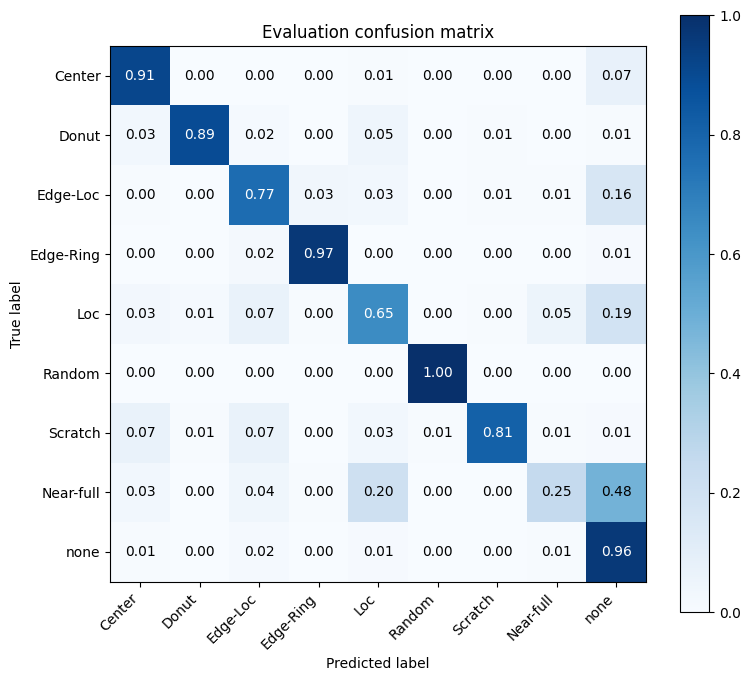

full test loss: 0.43332850811591067
full test accuracy: 0.9417750795027464
Per-class precision, recall, and F1:
  Class 0: precision=0.9419, recall=0.9126, F1=0.9270
  Class 1: precision=0.9206, recall=0.8923, F1=0.9062
  Class 2: precision=0.8779, recall=0.7656, F1=0.8180
  Class 3: precision=0.9792, recall=0.9668, F1=0.9730
  Class 4: precision=0.8194, recall=0.6471, F1=0.7231
  Class 5: precision=0.9412, recall=1.0000, F1=0.9697
  Class 6: precision=0.9299, recall=0.8111, F1=0.8665
  Class 7: precision=0.5833, recall=0.2510, F1=0.3510
  Class 8: precision=0.0000, recall=0.0000, F1=0.0000
Macro precision: 0.7771 - Macro recall: 0.6941 - Mean F1 (macro): 0.7260


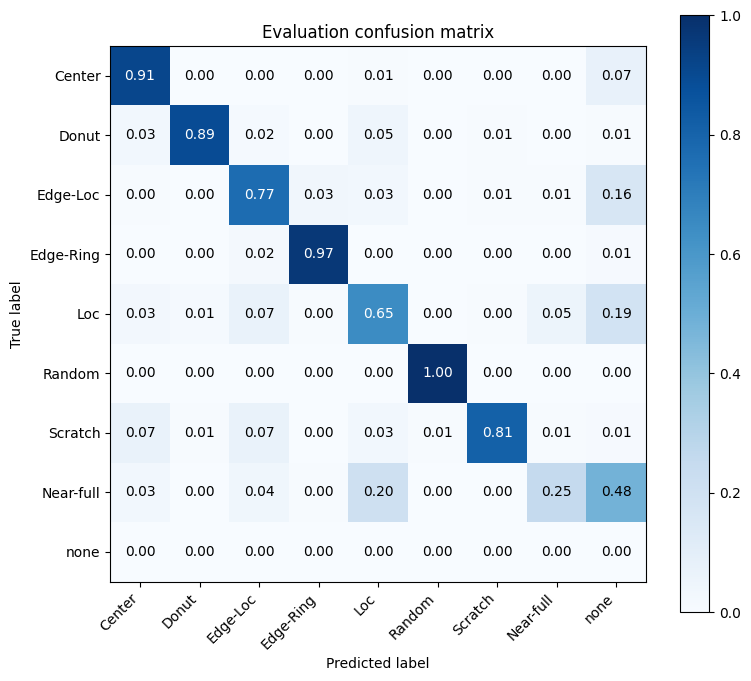

Pattern loss: 1.7657855112001435
Pattern accuracy: 0.8300512012603387


In [78]:
loss, accuracy = _evaluate_cnn(
        classifier, _to_nchw(x_test), _class_indices(y_test), nn.CrossEntropyLoss(), DEVICE, plot_confusion=True
    )
print("full test loss:", loss)
print("full test accuracy:", accuracy)
loss, accuracy = _evaluate_cnn(
        classifier, _to_nchw(x_pattern), _class_indices(y_pattern), nn.CrossEntropyLoss(), DEVICE, plot_confusion=True
    )
print("Pattern loss:", loss)
print("Pattern accuracy:", accuracy)

In [104]:
x_test.shape, y_test.shape

((34590, 26, 26, 3), (34590, 9))

In [110]:
x_test_linear = np.argmax(x_test, axis=3)
y_test_linear = np.argmax(y_test, axis=1)
print("x_test_linear shape:", x_test_linear.shape)
print("y_test_linear shape:", y_test_linear.shape) 

x_test_linear shape: (34590, 26, 26)
y_test_linear shape: (34590,)


In [116]:
y_test_linear = y_test_linear.astype(str)

In [119]:
for i,f in enumerate(faulty_case):
        y_test_linear[y_test_linear == str(i)]=f

In [120]:
y_test_linear

array(['none', 'none', 'none', ..., 'none', 'none', 'Edge-Ring'],
      dtype='<U21')

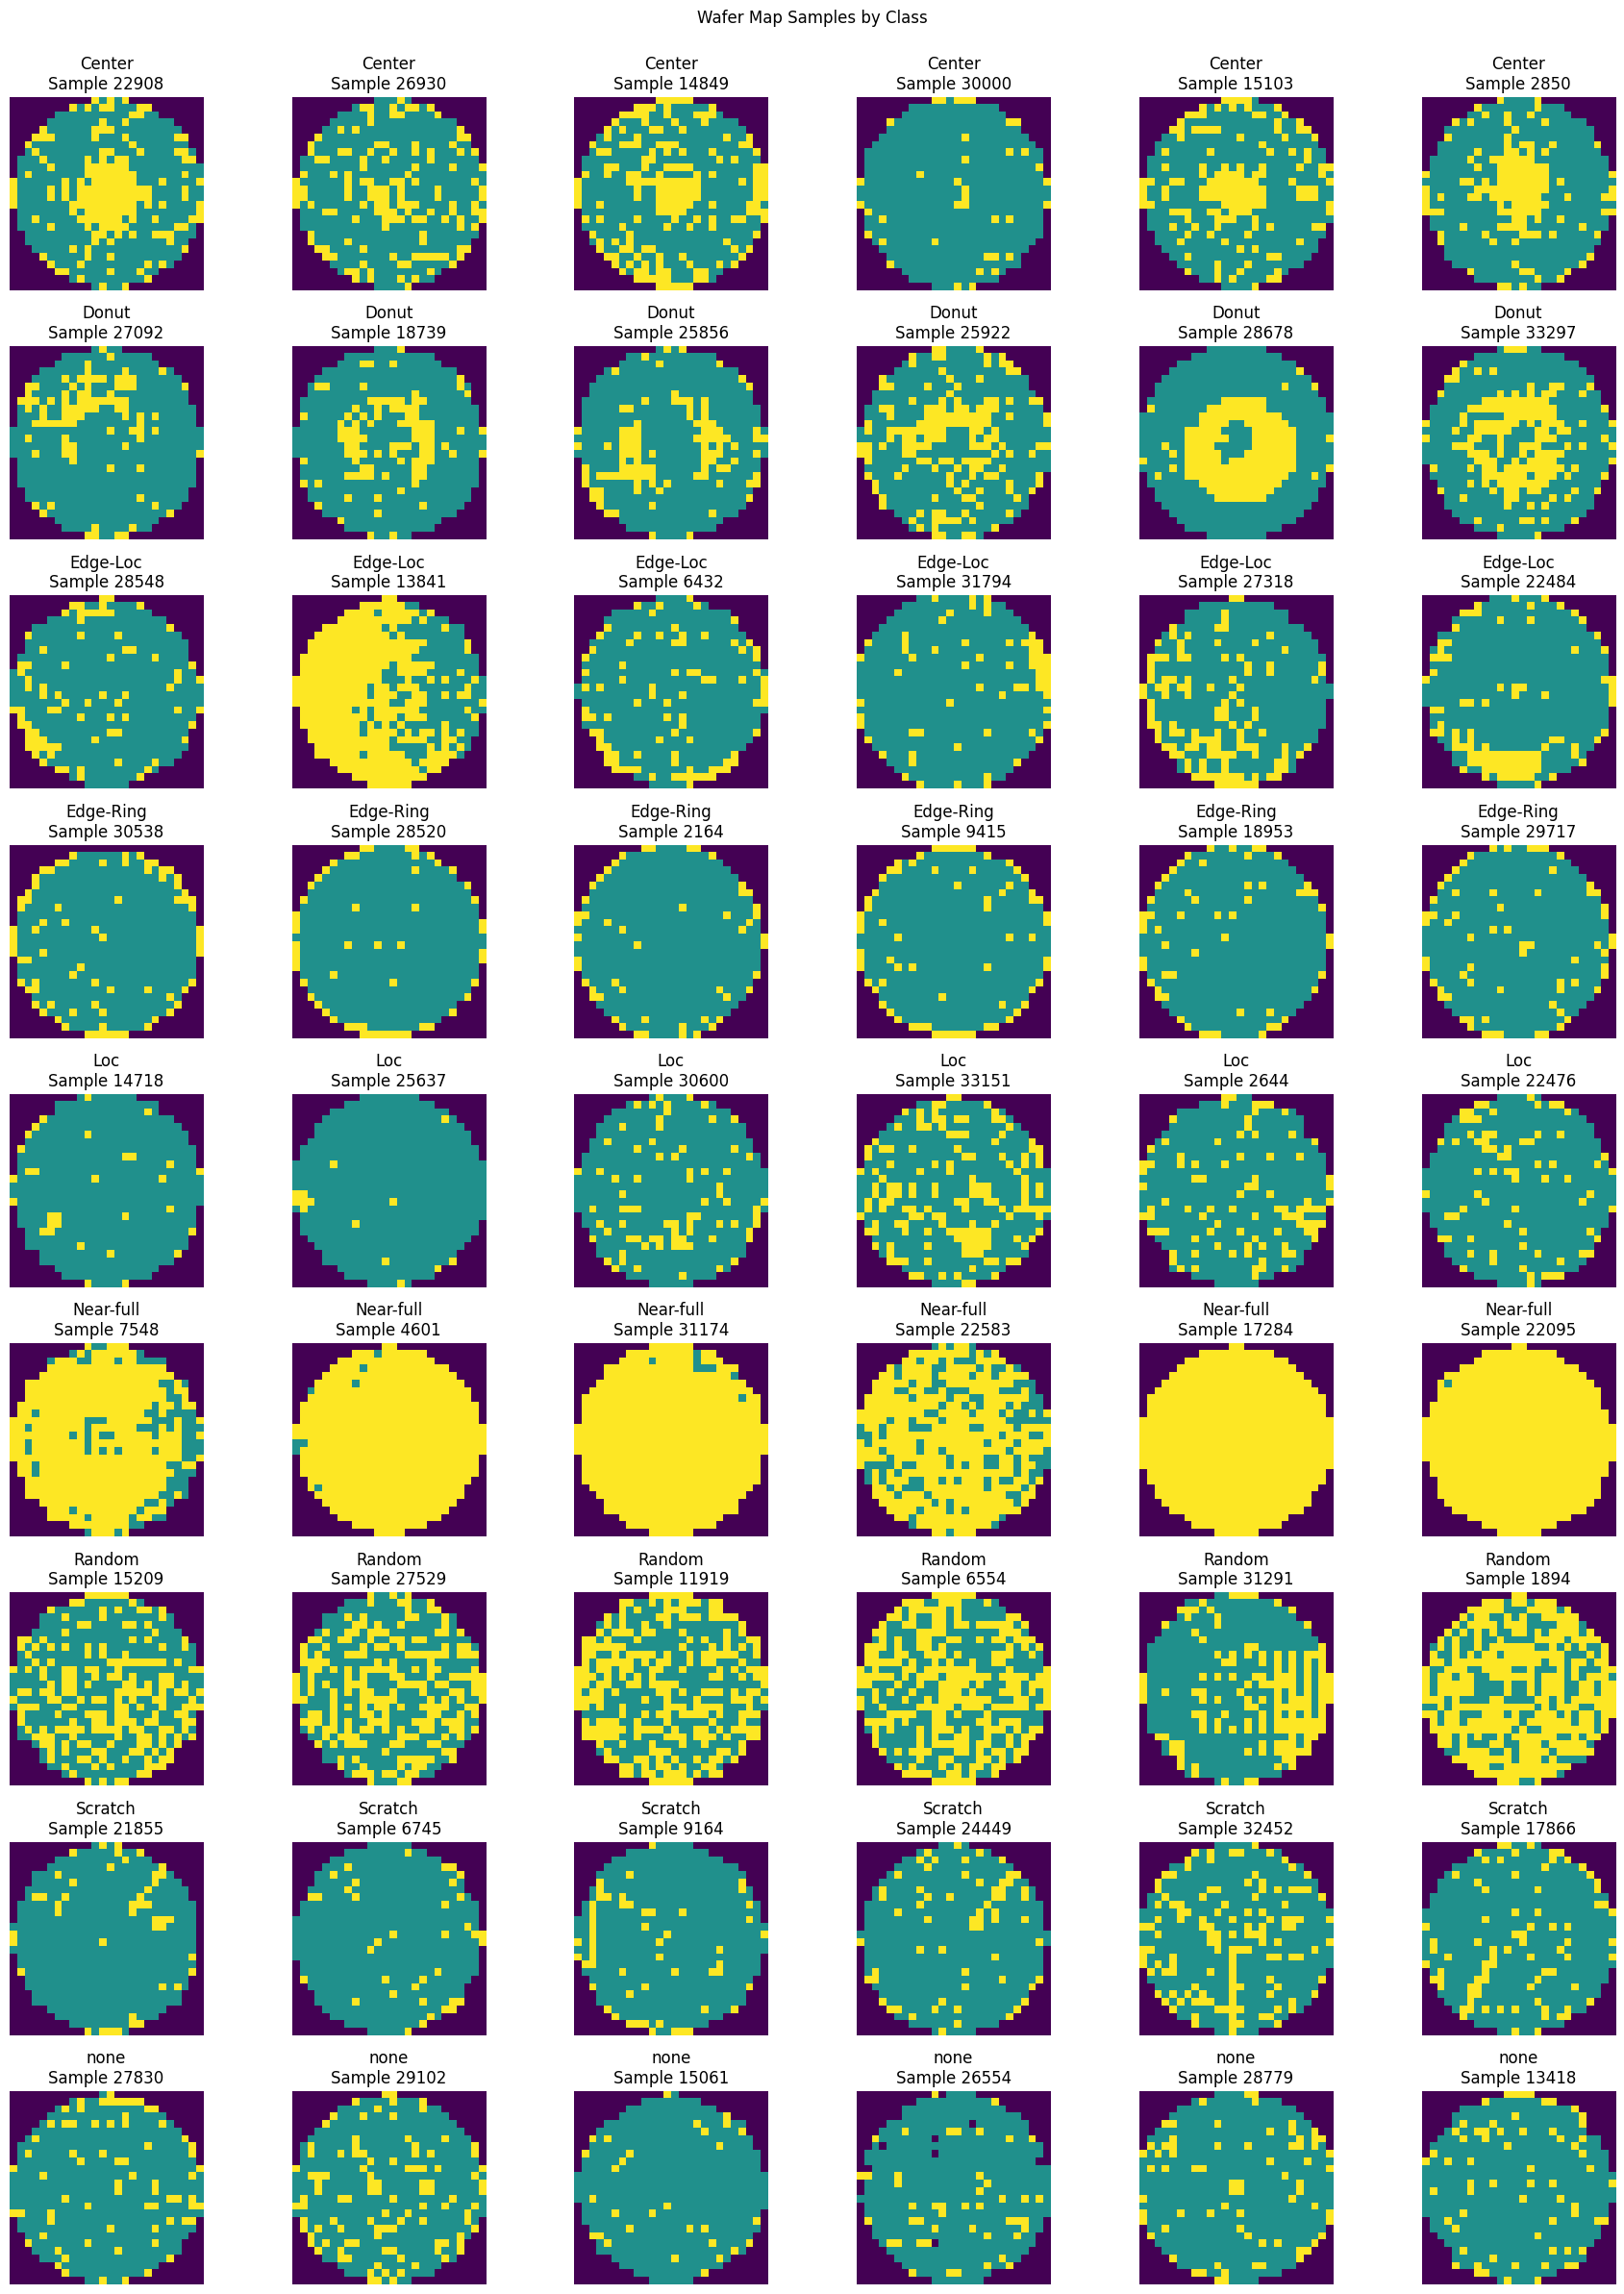

(<Figure size 1800x2430 with 54 Axes>,
 array([[<Axes: title={'center': 'Center\nSample 22908'}>,
         <Axes: title={'center': 'Center\nSample 26930'}>,
         <Axes: title={'center': 'Center\nSample 14849'}>,
         <Axes: title={'center': 'Center\nSample 30000'}>,
         <Axes: title={'center': 'Center\nSample 15103'}>,
         <Axes: title={'center': 'Center\nSample 2850'}>],
        [<Axes: title={'center': 'Donut\nSample 27092'}>,
         <Axes: title={'center': 'Donut\nSample 18739'}>,
         <Axes: title={'center': 'Donut\nSample 25856'}>,
         <Axes: title={'center': 'Donut\nSample 25922'}>,
         <Axes: title={'center': 'Donut\nSample 28678'}>,
         <Axes: title={'center': 'Donut\nSample 33297'}>],
        [<Axes: title={'center': 'Edge-Loc\nSample 28548'}>,
         <Axes: title={'center': 'Edge-Loc\nSample 13841'}>,
         <Axes: title={'center': 'Edge-Loc\nSample 6432'}>,
         <Axes: title={'center': 'Edge-Loc\nSample 31794'}>,
         <Axes:

In [123]:
show_images_by_class(x_test_linear, y_test_linear)

np.int64(1)

In [2]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
# Calculate weights based on your training labels array
# This penalizes the model heavily if it gets a rare defect wrong
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(zip(np.unique(y_train), class_weights))


NameError: name 'y_train' is not defined

In [56]:
x_test.shape

(34590, 26, 26, 3)

In [42]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/models/me0hu0l/plain-cnn-baseline-wm-811k/pytorch/default/1/plain_cnn_classifier_v1.pth
/kaggle/input/datasets/qingyi/wm811k-wafer-map/LSWMD.pkl


In [44]:
classifier = CNN()
state_dict = torch.load('/kaggle/input/models/me0hu0l/plain-cnn-baseline-wm-811k/pytorch/default/1/plain_cnn_classifier_v1.pth', torch.device('cpu'), weights_only=True)
classifier.load_state_dict(state_dict)
classifier.eval()

CNN(
  (network): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=86528, out_features=512, bias=True)
    (8): ReLU()
    (9): Linear(in_features=512, out_features=128, bias=True)
    (10): ReLU()
    (11): Linear(in_features=128, out_features=9, bias=True)
  )
)

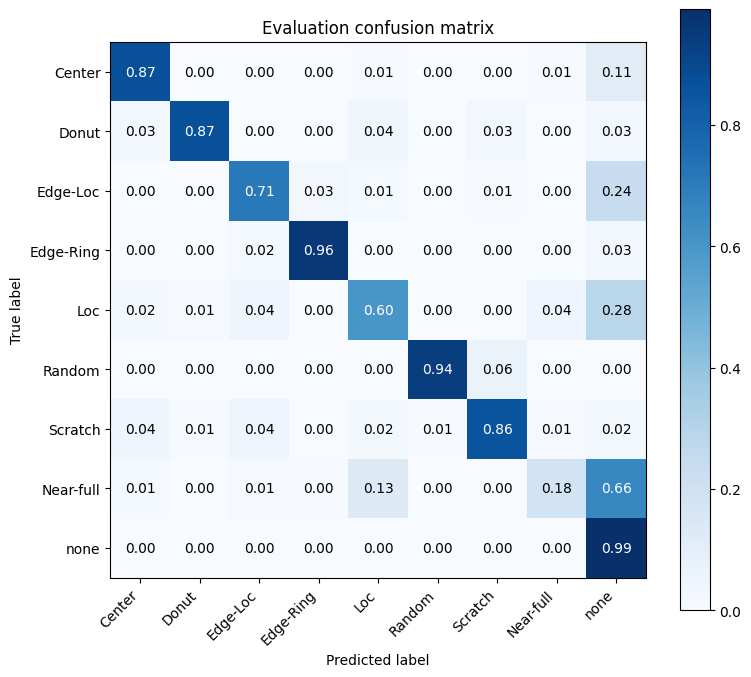

Test loss: 0.3740278927257689
Test accuracy: 0.9628794449262793


In [ ]:
loss, accuracy = _evaluate_cnn(
        classifier, _to_nchw(x_test), _class_indices(y_test), nn.CrossEntropyLoss(), DEVICE, plot_confusion=True
    )
print("Test loss:", loss)
print("Test accuracy:", accuracy)

In [48]:
x_train.shape

(138360, 26, 26, 3)

In [147]:
# start training the autoencoder on only x_train to preserve the integrity of x_test
ae, history = train_autoencoder(x_train)

Epoch 01/30 - loss: 0.052422 - 279.7s
Epoch 02/30 - loss: 0.015025 - 280.1s
Epoch 03/30 - loss: 0.008317 - 280.5s


KeyboardInterrupt: 

# only 26x26 work 

In [20]:
sub_df = df.loc[df['waferMapDim'] == (26,26)]
sub_wafer = sub_df['waferMap'].values
sub_wafer.shape

(30078,)

In [21]:
sw = np.ones((1,26,26))
label = list()
# collecting all the 26x26 wafer maps with non-null failure types
for i in range(len(sub_df)):
        # skip null label
        if len(sub_df.iloc[i,:]['failureType']) ==0:
                continue
        sw = np.concatenate((sw, sub_df.iloc[i,:]['waferMap'].reshape(1,26,26)))
        label.append(sub_df.iloc[i,:]['failureType'][0][0])

In [22]:
x = sw[1:]
y = np.array(label).reshape((-1,1))

In [23]:
print(f"x shape: {x.shape}, y shape: {y.shape}")

x shape: (14366, 26, 26), y shape: (14366, 1)


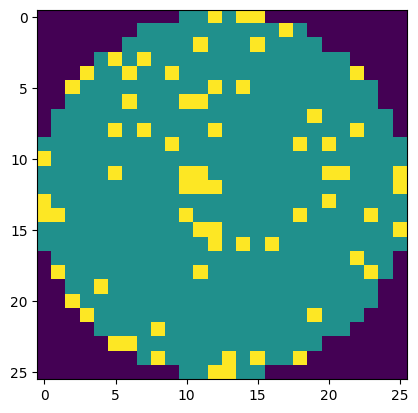

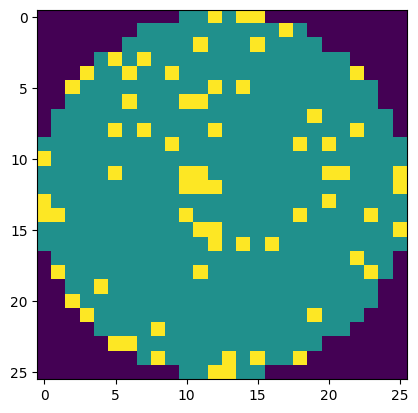

label: ['none']


In [24]:
# plot any wafer
plt.imshow(x[2040])
plt.show()

# check the label of the plotted wafer
print(f"label: {y[2040]}")

In [25]:
x = x.reshape(-1,26,26,1) # NHWC format

In [26]:
faulty_case = np.unique(y)
print(f"faulty cases: {faulty_case}")

faulty cases: ['Center' 'Donut' 'Edge-Loc' 'Edge-Ring' 'Loc' 'Near-full' 'Random'
 'Scratch' 'none']


In [29]:
for f in faulty_case:
        print('{} : {}'.format(f, len(y[y==f])))

Center : 90
Donut : 1
Edge-Loc : 296
Edge-Ring : 31
Loc : 297
Near-full : 16
Random : 74
Scratch : 72
none : 13489


In [30]:
# one hot encoding the wafer map data
new_x = np.zeros((len(x),26,26,3))

for w in range(len(x)):
    for i in range(26):
        for j in range(26):
            new_x[w, i, j, int(x[w, i, j])] = 1

/tmp/ipykernel_145/3656758309.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  new_x[w, i, j, int(x[w, i, j])] = 1


In [31]:
new_x.shape

(14366, 26, 26, 3)

In [34]:
from sklearn.model_selection import KFold 
from sklearn.model_selection import cross_val_score

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from keras.utils import to_categorical


In [35]:
new_y =y
for i,l in enumerate(faulty_case):
        new_y[new_y==l] = i
# one-hot encoding

new_y = to_categorical(new_y)


In [38]:
print(f"new_x shape: {new_x.shape}")
print(f"new_y shape: {new_y.shape}")

new_x shape: (14366, 26, 26, 3)
new_y shape: (14366, 9)


In [42]:
# splitting the dataset early into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(new_x, new_y, test_size=0.2, random_state=2026)
print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: (11492, 26, 26, 3)
x_test shape: (2874, 26, 26, 3)
y_train shape: (11492, 9)
y_test shape: (2874, 9)


In [54]:
print("Faulty case counts in training  vs testing set:")
for i,f in enumerate(faulty_case):
        print('{}: {} : {}'.format(f,np.sum(y_train[:,i]==1),np.sum(y_test[:,i]==1)))
print(f"total wafers: {y_train.shape[0]} : {y_test.shape[0]}")
# print("Faulty case counts in testing set:")
# for i,f in enumerate(faulty_case):
#         print('{}:{}'.format(f,np.sum(y_test[:,i]==1)))

Faulty case counts in training  vs testing set:
Center: 75 : 15
Donut: 1 : 0
Edge-Loc: 230 : 66
Edge-Ring: 23 : 8
Loc: 232 : 65
Near-full: 15 : 1
Random: 62 : 12
Scratch: 57 : 15
none: 10797 : 2692
total wafers: 11492 : 2874


In [59]:
df_withlabel.shape, df_withpattern.shape

((172950, 9), (25519, 9))

In [57]:
df[df['failureType']=='Donut'].waferMapDim.value_counts()

waferMapDim
(41, 42)    234
(35, 31)     98
(35, 40)     33
(45, 50)     23
(39, 37)     22
(54, 71)     17
(44, 41)     12
(59, 67)     11
(57, 58)      9
(45, 43)      8
(37, 55)      8
(56, 41)      7
(27, 25)      6
(32, 29)      6
(51, 44)      5
(49, 39)      5
(54, 42)      5
(37, 31)      4
(30, 34)      4
(30, 30)      3
(41, 33)      2
(43, 44)      2
(33, 29)      2
(45, 46)      2
(63, 62)      2
(33, 33)      2
(39, 44)      2
(63, 76)      2
(31, 31)      2
(40, 40)      2
(29, 26)      2
(37, 37)      1
(87, 74)      1
(76, 71)      1
(79, 80)      1
(44, 44)      1
(53, 59)      1
(72, 72)      1
(58, 53)      1
(52, 51)      1
(26, 26)      1
(38, 38)      1
(25, 26)      1
(42, 44)      1
Name: count, dtype: int64

In [73]:
resized = preprocess_wafer(dummy.iloc[0]['waferMap'])
dummy.iloc[0]['waferMap'].shape
resized.shape

(26, 26)

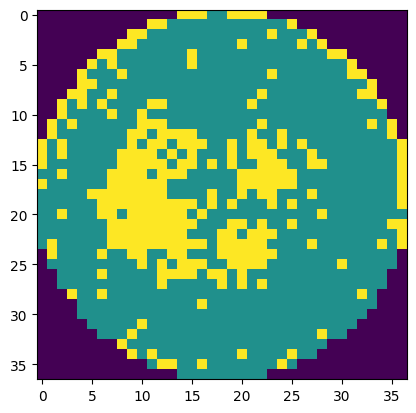

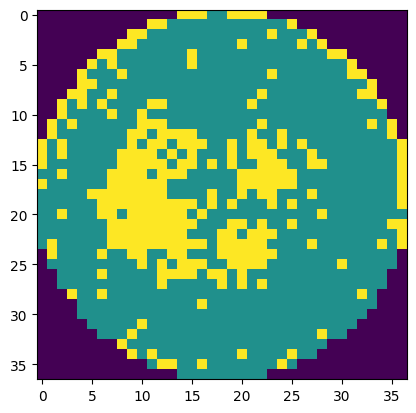

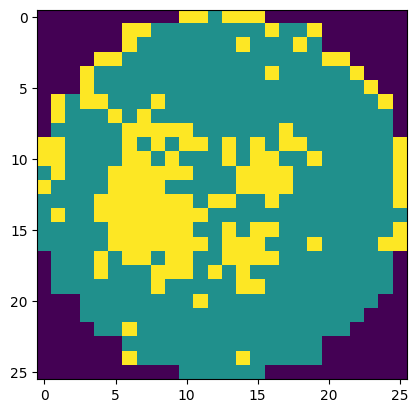

In [72]:
plt.imshow(dummy.iloc[0]['waferMap'])
plt.show()
plt.imshow(resized)
plt.show()

In [81]:
dummy_list = dummy['waferMap'].to_list()
resized = bulk_resize_wafers(dummy_list, target_shape=(26, 26), n_jobs=-1)

🚀 Processing 555 wafers using all CPU cores...


🚀 Processing 555 wafers using all CPU cores...


0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0

In [82]:
resized.shape

(555, 26, 26)

In [63]:
dummy = df_withpattern[df_withpattern['failureType'] == 'Donut']
dummy

,index,waferMap,dieSize,lotName,trianTestLabel,failureType,waferMapDim,failureNum,trainTestNum
255,7316,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2,...",1091.0,lot490,[[Training]],[[Donut]],"(37, 37)",1,0
257,7334,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1620.0,lot534,[[Training]],[[Donut]],"(37, 55)",1,0
258,7335,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1620.0,lot534,[[Training]],[[Donut]],"(37, 55)",1,0
259,7338,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1620.0,lot534,[[Training]],[[Donut]],"(37, 55)",1,0
260,7339,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1620.0,lot534,[[Training]],[[Donut]],"(37, 55)",1,0
...,...,...,...,...,...,...,...,...,...
24090,782753,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1414.0,lot46376,[[Test]],[[Donut]],"(42, 44)",1,1
24751,800962,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1, 2,...",562.0,lot47114,[[Test]],[[Donut]],"(29, 26)",1,1
24754,800986,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1, 1, 1,...",562.0,lot47115,[[Test]],[[Donut]],"(29, 26)",1,1
24894,805595,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,...",1060.0,lot47303,[[Test]],[[Donut]],"(41, 33)",1,1
